In [ ]:
# Kernell - python anaconda 3.12.7

# Загрузим библиотеки
# Let's load the libraries

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklift.models import SoloModel, TwoModels

import pickle

from catboost import CatBoostClassifier, CatBoostRegressor
from causalml.inference.meta import BaseXClassifier, BaseRClassifier
from sklearn.linear_model import LinearRegression

from causalml.inference.tree import UpliftTreeClassifier, UpliftRandomForestClassifier
from causalml.inference.tree import uplift_tree_string, uplift_tree_plot

import warnings
warnings.filterwarnings('ignore')

## **Знакомство с данными**

## **Getting to Know the Data**

In [ ]:
# Читаем файл с результатами uplift-моделирования на данных о скидках
# Read the file with the results of uplift modeling on discount data
df_data = pd.read_csv('criteo-uplift.csv')

df_data

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13979587,26.297764,10.059654,9.006250,4.679882,10.280525,4.115453,-3.282109,4.833815,3.839578,13.190056,5.300375,-0.168679,1,0,0,0
13979588,12.642207,10.679513,8.214383,-1.700105,10.280525,3.013064,-13.955150,6.269026,3.971858,13.190056,5.300375,-0.168679,1,0,0,1
13979589,12.976557,10.059654,8.381868,0.842442,11.029584,4.115453,-8.281971,4.833815,3.779212,23.570168,6.169187,-0.168679,1,0,1,0
13979590,24.805064,10.059654,8.214383,4.679882,10.280525,4.115453,-1.288207,4.833815,3.971858,13.190056,5.300375,-0.168679,1,0,0,0


Наш датасет состоит из 12 столбцов - факторов, описывающих параметры объекта **f0 - f11** и четыре столбца с бинарными значениями:

- *treatment* - обработка

treatment: treatment group (1 = treated, 0 = control)

- *conversion* - преобразование

conversion: whether a conversion occured for this user (binary, label)

- *visit*

visit: whether a visit occured for this user (binary, label) 

- *exposure*

exposure: treatment effect, whether the user has been effectively exposed (binary)
______________________________________________________________________________________________________________________________________________________________________

Our dataset consists of 12 columns—factors describing the object parameters **f0–f11**—and four columns with binary values:

- *treatment*: treatment group (1 = treated, 0 = control)

- *conversion*: whether a conversion occured for this user (binary, label)

- *visit*: whether a visit occured for this user (binary, label)

- *exposure*: treatment effect, whether the user has been effectively exposed (binary)

Проверим теорию, что если в строке признак ‘visit’ == 1, то признак признак ‘treatment’ обязательно будет равен 1
___________________________________________________________________________________________________________________

Let's test the theory that if the 'visit' attribute in a string is 1, then the 'treatment' attribute will definitely be equal to 1.

In [3]:
visit_treatment = df_data[df_data['visit'] == 1]['treatment']
if np.all(visit_treatment == 1):
    print("Hypothesis is true: if 'visit' is 1, then 'treatment' is also 1")
else:
    print("Hypothesis is false")

Hypothesis is false


Проверим теорию, что если в строке признак ‘conversion’ == 1, то признак ‘treatment’ обязательно будет равен 1
__________________________________________________________________________________________________________________________

Let's test the theory that if the 'conversion' attribute in a row is 1, then the 'treatment' attribute will definitely be equal to 1.

In [4]:
conversion_treatment = df_data[df_data['conversion'] == 1]['treatment']
if np.all(conversion_treatment == 1):
    print("Hypothesis is true: if 'conversion' is 1, then 'treatment' is also 1")
else:
    print("Hypothesis is false")

Hypothesis is false


In [ ]:
# доля конверсии среди записей датасета - 0,2 %
# conversion rate among dataset records - 0.2%

df_data['conversion'].sum()/df_data['conversion'].count()

0.002916680257907384

In [ ]:
# доля объектов, получивших взаимодействие, среди записей датасета - 85 %
# the proportion of objects that received interaction among the dataset records is 85%

df_data['treatment'].sum()/df_data['treatment'].count()

0.8500001287591226

In [ ]:
# доля клиентов, к которым был осуществлен визит - 4,7 %
# share of clients visited - 4.7%

df_data['visit'].sum()/df_data['visit'].count()

0.046992000911042324

In [ ]:
# Эффект эффективного взаимодействия (улучшение мнения о товаре у потенциального клиента), независимо от того, был ли пользователь эффективно подвергнут воздействию - 3.1 %
# Effect of effective interaction (improving the potential customer's opinion of the product), regardless of whether the user was effectively exposed to the influence - 3.1%

df_data['exposure'].sum()/df_data['exposure'].count()

0.03063122299992732

Проверим теорию, что если в строке признак ‘exposure’ == 1, то признак признак ‘treatment’ == 1
________________________________________________________________________________________________________________________

Let's test the theory that if the 'exposure' attribute in a string == 1, then the 'treatment' attribute == 1

In [9]:
treatment_exposure = df_data[df_data['treatment'] == 1]['exposure']
if np.all(treatment_exposure == 1):
    print("Hypothesis is true: if 'treatment' is 1, then 'exposure' is also 1")
else:
    print("Hypothesis is false")

Hypothesis is false


Нужно проверить теорию, что если в строке признак ‘exposure’ == 0, то признак признак ‘visit’ == 1
__________________________________________________________________________________________________________

We need to test the theory that if the 'exposure' attribute in a string == 0, then the 'visit' attribute == 1

In [10]:
visit_exposure = df_data[df_data['visit'] == 1]['exposure']
if np.all(visit_exposure == 0):
    print("Hypothesis is true: if 'visit' is 1, then 'exposure' is 0")
else:
    print("Hypothesis is false")

Hypothesis is false


**Небольшие предварительные выводы:**

Как я понял - *treatment* и *visit* - это бинарные признаки, говорящие о воздействии: 1 - было, 0 - не было,

а *conversion* и *exposure* - это соответствующие им признаки, говорящие о наличии/отсутствии uplift эффекта, также принимающие значения: 1 - есть, 0 -нет.

В датасете присутствуют все возможные комбинации 1 и 0 по признакам *treatment*, *visit*, *conversion* и *exposure*.

Мы будем изучать uplift эффект на уровне взхаимодействий *treatment - conversion* (побудило ли взаимодействие с клиентом к совершению им нужного нам действия) и *visit - exposure* 
(улучшил ли визит к клиенту отношение клиента к продукции).
____________________________________________________________________________________________________________________________

**Small preliminary conclusions:**

As I understand it, *treatment* and *visit* are binary indicators indicating the impact: 1 - there was, 0 - there was not.

The dataset contains all possible combinations of 1 and 0 for the features *treatment*, *visit*, *conversion* and *exposure*.

We will study the uplift effect at the level of interactions *treatment - conversion* (whether interaction with the client prompted them to take the action we wanted) and *visit - exposure* (whether the visit to the client improved the client's attitude towards the product).

In [ ]:
# Для удобства создадим отдельный датасет для изучения эффекта treatment - conversion
# For convenience, we will create a separate dataset to study the treatment-conversion effect

df_data_treatment_conversion = df_data.drop(['visit', 'exposure'], axis=1).reset_index(drop=True)

df_data_treatment_conversion

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13979587,26.297764,10.059654,9.006250,4.679882,10.280525,4.115453,-3.282109,4.833815,3.839578,13.190056,5.300375,-0.168679,1,0
13979588,12.642207,10.679513,8.214383,-1.700105,10.280525,3.013064,-13.955150,6.269026,3.971858,13.190056,5.300375,-0.168679,1,0
13979589,12.976557,10.059654,8.381868,0.842442,11.029584,4.115453,-8.281971,4.833815,3.779212,23.570168,6.169187,-0.168679,1,0
13979590,24.805064,10.059654,8.214383,4.679882,10.280525,4.115453,-1.288207,4.833815,3.971858,13.190056,5.300375,-0.168679,1,0


In [ ]:
# Для удобства создадим отдельный датасет для изучения эффекта visit - exposure
# For convenience, we will create a separate dataset to study the visit-exposure effect

df_data_visit_exposure = df_data.drop(['treatment', 'conversion'], axis=1).reset_index(drop=True)

df_data_visit_exposure

,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,visit,exposure
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,0,0
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,0,0
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,0,0
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,0,0
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13979587,26.297764,10.059654,9.006250,4.679882,10.280525,4.115453,-3.282109,4.833815,3.839578,13.190056,5.300375,-0.168679,0,0
13979588,12.642207,10.679513,8.214383,-1.700105,10.280525,3.013064,-13.955150,6.269026,3.971858,13.190056,5.300375,-0.168679,0,1
13979589,12.976557,10.059654,8.381868,0.842442,11.029584,4.115453,-8.281971,4.833815,3.779212,23.570168,6.169187,-0.168679,1,0
13979590,24.805064,10.059654,8.214383,4.679882,10.280525,4.115453,-1.288207,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0


## **Построение моделей S-learner**

## **Building S-learner models**

In [ ]:
# Разделим данные на обучающую и валидационную выборки для обоих датасетов
# We will split the data into training and validation sets for both datasets

train_treat_conv, val_treat_conv = train_test_split(df_data_treatment_conversion, test_size=0.2, random_state=42)

train_visit_expose, val_visit_expose = train_test_split(df_data_visit_exposure, test_size=0.2, random_state=42)

In [ ]:
# функция берущая, обученный датасет и возвращающая датасет ranked, служащий для расчета qini score  и визуализации qini curve
# a function that takes a trained dataset and returns a ranked dataset, which is used to calculate the qini score and visualize the qini curve

def qini_calculate (df, conversion = 'conversion'):
    # Отранжируем выборку по значению uplift в убывающем порядке
    # Rank the sample by uplift value in descending order
    ranked = df.sort_values("uplift_score", ascending=False)
    
    N_c = sum(ranked[conversion] == 0)
    N_t = sum(ranked[conversion] == 1)
    
    # Посчитаем в отсортированном датафрейме основные показатели, которые используются при расчете qini
    # Let's calculate the main indicators used in calculating qini in the sorted data frame
    ranked['n_c1'] = 0
    ranked['n_t1'] = 0
    ranked.loc[ranked[conversion] == 1,'n_t1'] = 1
    ranked['n_c1/nc'] = ranked.n_c1.cumsum() / N_c
    ranked['n_t1/nt'] = ranked.n_t1.cumsum() / N_t
    
    # Посчитаем qini curve и рандомную прямую под ней
    # Let's calculate the qini curve and a random line under it
    ranked['uplift'] = round(ranked['n_t1/nt'] - ranked['n_c1/nc'],5)
    # Добавим случайную кривую
    # Add a random curve
    ranked['random_uplift'] = round(ranked["uplift_score"].rank(pct=True, ascending=False) * ranked['uplift'].iloc[-1],5)
    
    ranked["n"] = ranked["uplift_score"].rank(pct=True, ascending=False)     
    return ranked

# функция считает qini score на основе данных вспомогательного датасета ranked, полученного в qini_calculate функции
# the function calculates the qini score based on the data from the auxiliary dataset ranked, obtained in the qini_calculate function
def qini_count(ranked):
	return (ranked['uplift'] - ranked['random_uplift']).sum()

# функция рисует qini curve на основе данных вспомогательного датасета ranked, полученного в qini_calculate функции
# the function draws a qini curve based on the data of the auxiliary dataset ranked, obtained in the qini_calculate function  
def qini_visual(ranked, title = 'train', figsize=(5, 3)):
    fig = plt.figure(figsize=figsize)
    plt.plot(ranked['n'], ranked['uplift'], color='r', label='Model')
    plt.plot(ranked['n'], ranked['random_uplift'], color='b', label='RandomModel')
    plt.legend()
    plt.title('Qini-curve for {} samples'.format(title))
    plt.show()

In [ ]:
# Создаем базовый S-learner для visit-expose поддатасета
# Create a basic S-learner for the visit-expose subdataset
s_learner_visit = SoloModel(
    estimator=CatBoostClassifier(random_seed=13, verbose=0)
)

# Для обучения нам нужны датафрейм с факторами, таргет и колонка с фактом воздействия
# For training, we need a dataframe with features, target, and a column with the treatment indicator
feature_cols = ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']
target_col = 'exposure'
treatment_col = 'visit'

s_learner_visit = s_learner_visit.fit(
    X=train_visit_expose[feature_cols],
    y=train_visit_expose[target_col],
    treatment=train_visit_expose[treatment_col]
)

# Сделаем предсказание uplift-эффекта на обучающей выборке
# Let's make a prediction of the uplift effect on the training sample
uplift_vals = s_learner_visit.predict(train_visit_expose[feature_cols])
train_visit_expose['uplift_score'] = uplift_vals

# Сделаем предсказание uplift-эффекта на валидационной выборке
# Let's make a prediction of the uplift effect on the validation sample
uplift_vals = s_learner_visit.predict(val_visit_expose[feature_cols])
val_visit_expose['uplift_score'] = uplift_vals

In [ ]:
# записываем, получившуюся модель в pkl файл
# write the resulting model to a pkl file

with open('s_learner_visit.pkl', 'wb') as f:
    pickle.dump(s_learner_visit, f)

In [ ]:
# реализуем функцию qini_calculate на тренировочной и валидационной выборках
# implement the qini_calculate function on the training and validation samples
ranked_train = qini_calculate(train_visit_expose, conversion = 'exposure')
ranked_val = qini_calculate(val_visit_expose, conversion = 'exposure')

Qini score visit - exposure for train set: 2465367.446


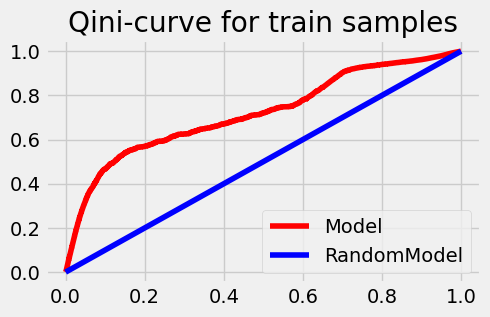

Qini score visit - exposure for validation set: 608991.155


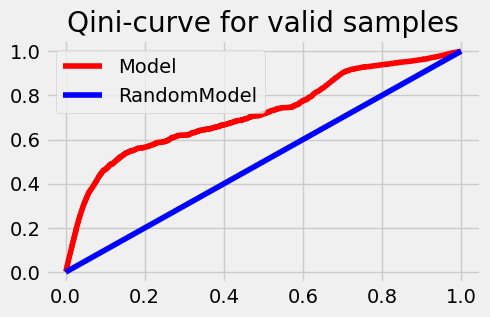

In [ ]:
# раcсчитываем quni score и рисуем qini curve на тренировочном и валидационном датасетах
# calculate the qini score and draw the qini curve on the training and validation datasets

print('Qini score visit - exposure for train set: {:.3f}'.format(qini_count(ranked_train)))
qini_visual(ranked_train)

print('Qini score visit - exposure for validation set: {:.3f}'.format(qini_count(ranked_val)))
qini_visual(ranked_val, title = 'valid')

Рисунки обоих кривых визуально совпадают - это говорит, что модель на валидационной выборке подтверждает предсказания на тренировочной выборке.
______________________________________________________________________________________________________________________________________________

The figures of both curves visually coincide, which indicates that the model on the validation set confirms the predictions on the training set.

In [ ]:
# создаем датасет для анализа результатов работы моделей visit-expose и записываем в него результат работы первой модели
# create a dataset to analyze the results of the visit-expose models and write the result of the first model to it

Uplift_models_compare_visit_exposure = pd.DataFrame({
    'Model': pd.Series(dtype=object),
    'Qini score train': pd.Series(dtype=float),
    'Qini score validation': pd.Series(dtype=float)
})

new_row = pd.DataFrame({
    'Model': ['S - learner'],
    'Qini score train': [round(qini_count(ranked_train), 3)],
    'Qini score validation': [round(qini_count(ranked_val), 3)]
})

Uplift_models_compare_visit_exposure = pd.concat([Uplift_models_compare_visit_exposure, new_row], ignore_index=True)

Uplift_models_compare_visit_exposure

,Model,Qini score train,Qini score validation
0,S - learner,2465367.446,608991.155


In [ ]:
# Создаем базовый S-learner для treatment-conversion поддатасета
# Create a basic S-learner for the treatment-conversion subdataset
s_learner_treatment = SoloModel(
    estimator=CatBoostClassifier(random_seed=13, verbose=0)
)


# Для обучения нам нужны датафрем с факторами, таргет и колонка с фактом воздействия
# For training, we need a dataframe with features, target, and a column with the treatment indicator
feature_cols = ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']
target_col = 'conversion'
treatment_col = 'treatment'

s_learner_treatment = s_learner_treatment.fit(
    X=train_treat_conv[feature_cols],
    y=train_treat_conv[target_col],
    treatment=train_treat_conv[treatment_col]
)

# Сделаем предсказание uplift-эффекта на обучающей выборке
# Let's make a prediction of the uplift effect on the training sample
uplift_vals = s_learner_treatment.predict(train_treat_conv[feature_cols])
train_treat_conv['uplift_score'] = uplift_vals

# Сделаем предсказание uplift-эффекта на валидационной выборке
# Let's make a prediction of the uplift effect on the validation sample
uplift_vals = s_learner_treatment.predict(val_treat_conv[feature_cols])
val_treat_conv['uplift_score'] = uplift_vals

In [ ]:
# записываем, получившуюся модель в pkl файл
# write the resulting model to a pkl file

with open('s_learner_treatment.pkl', 'wb') as f:
    pickle.dump(s_learner_treatment, f)

In [ ]:
# реализуем функцию qini_calculate на тренировочной и валидационной выборках
# implement the qini_calculate function on the training and validation samples
ranked_train = qini_calculate(train_treat_conv)
ranked_val = qini_calculate(val_treat_conv)

Qini score treatment - conversion for train set: 4693718.641


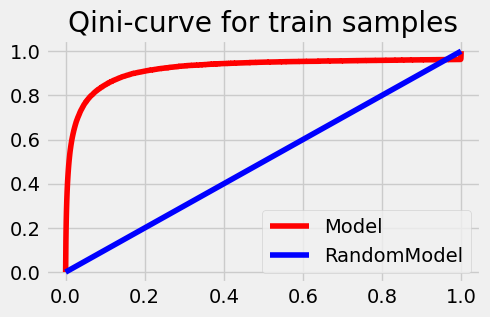

Qini score treatment - conversion for validation set: 1173650.714


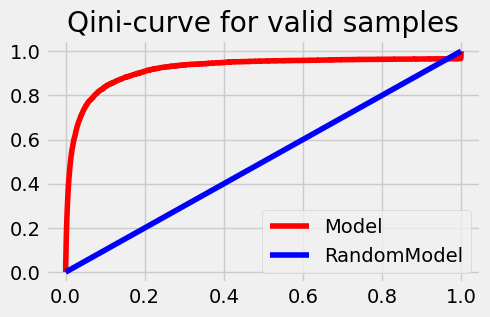

In [ ]:
# раcсчитываем quni score и рисуем qini curve на тренировочном и валидационном датасетах
# calculate the qini score and draw the qini curve on the training and validation datasets

print('Qini score treatment - conversion for train set: {:.3f}'.format(qini_count(ranked_train)))
qini_visual(ranked_train)

print('Qini score treatment - conversion for validation set: {:.3f}'.format(qini_count(ranked_val)))
qini_visual(ranked_val, title = 'valid')

Рисунки обоих кривых визуально совпадают - это говорит, что модель на валидационной выборке подтверждает предсказания на тренировочной выборке. Можно обратить внимание на "петельку" в конце *qini* кривой - я считаю это говорит о недостатке предсказания модели. *uplift* эффект на последнем отрезке отсортированных *uplift score* отрицателен.
_________________________________________________________________________________________________________________________________________________
The two curves visually match, indicating that the model's predictions on the validation set confirm those on the training set. Note the "loop" at the end of the qini curve—I believe this indicates a lack of model prediction. The uplift effect on the final segment of the sorted uplift score is negative.

In [ ]:
# создаем датасет для анализа результатов работы моделей и записываем в него результат первой модели
# create a dataset to analyze the results of the models and write the result of the first model to it

Uplift_models_compare_treatment_conversion = pd.DataFrame({
    'Model': pd.Series(dtype=object),
    'Qini score train': pd.Series(dtype=float),
    'Qini score validation': pd.Series(dtype=float)
})

new_row = pd.DataFrame({
    'Model': ['S - learner'],
    'Qini score train': [round(qini_count(ranked_train), 3)],
    'Qini score validation': [round(qini_count(ranked_val), 3)]
})

Uplift_models_compare_treatment_conversion = pd.concat([Uplift_models_compare_treatment_conversion, new_row], ignore_index=True)

Uplift_models_compare_treatment_conversion

,Model,Qini score train,Qini score validation
0,S - learner,4693718.641,1173650.714


## **Построение моделей T-learner**

## **Building T-learner models**

In [ ]:
# Создадим базовый T-learner для visit-expose датасета
# Create a basic T-learner for the visit-expose dataset
t_learner_visit = TwoModels(
    estimator_trmnt=CatBoostClassifier(random_seed=13, verbose=0),
    estimator_ctrl=CatBoostClassifier(random_seed=13, verbose=0)
)

# Для обучения нам нужны датафрем с факторами, таргет и колонка с фактом воздействия
# For training, we need a dataframe with features, target, and a column with the treatment indicator
feature_cols = ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']
target_col = 'exposure'
treatment_col = 'visit'


t_learner_visit = t_learner_visit.fit(
    X=train_visit_expose[feature_cols],
    y=train_visit_expose[target_col],
    treatment=train_visit_expose[treatment_col]
)

# Сделаем предсказание uplift-эффекта на тренировочной выборке
# Let's make a prediction of the uplift effect on the training sample
uplift_vals = t_learner_visit.predict(train_visit_expose[feature_cols])
train_visit_expose['uplift_score'] = uplift_vals

# Сделаем предсказание uplift-эффекта на валидационной выборке
# Let's make a prediction of the uplift effect on the validation sample
uplift_vals = t_learner_visit.predict(val_visit_expose[feature_cols])
val_visit_expose['uplift_score'] = uplift_vals

In [ ]:
# записываем, получившуюся модель в pkl файл
# write the resulting model to a pkl file

with open('t_learner_visit.pkl', 'wb') as f:
    pickle.dump(t_learner_visit, f)

In [ ]:
# реализуем функцию qini_calculate на тренировочной и валидационной выборках
# implement the qini_calculate function on the training and validation samples
ranked_train = qini_calculate(train_visit_expose, conversion = 'exposure')
ranked_val = qini_calculate(val_visit_expose, conversion = 'exposure')

Qini score visit - exposure for train set: 2031344.513


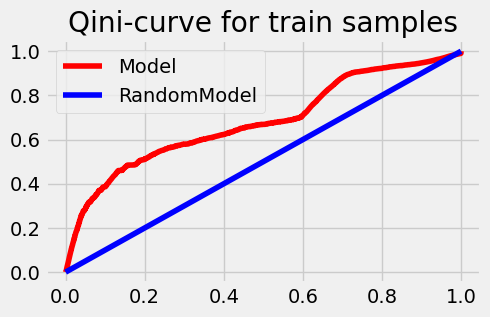

Qini score visit - exposure for validation set: 541990.935


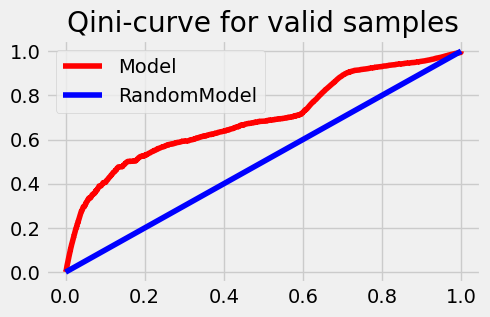

In [ ]:
# раcсчитываем qini score и рисуем qini curve на тренировочном и валидационном датасетах
# calculate the qini score and draw the qini curve on the training and validation datasets
print('Qini score visit - exposure for train set: {:.3f}'.format(qini_count(ranked_train)))
qini_visual(ranked_train)

print('Qini score visit - exposure for validation set: {:.3f}'.format(qini_count(ranked_val)))
qini_visual(ranked_val, title = 'valid')

Рисунки обоих кривых визуально совпадают - это говорит, что модель на валидационной выборке подтверждает предсказания на тренировочной выборке. Qini score по сравнению с S-моделью хуже.
___________________________________________________________________

The plots of both curves visually match, indicating that the model on the validation set confirms the predictions on the training set. The Qini score is worse than the S-model.

In [ ]:
# записываем в датасет для анализа результатов работы моделей результат работы T-learner
# write the result of the T-learner to the dataset for analyzing the results of the models

new_row = pd.DataFrame({
    'Model': ['T - learner'],
    'Qini score train': [round(qini_count(ranked_train), 3)],
    'Qini score validation': [round(qini_count(ranked_val), 3)]
})

Uplift_models_compare_visit_exposure = pd.concat([Uplift_models_compare_visit_exposure, new_row], ignore_index=True)

Uplift_models_compare_visit_exposure

,Model,Qini score train,Qini score validation
0,S - learner,2465367.446,608991.155
1,T - learner,2031344.513,541990.935


In [ ]:
# Создадим базовый T-learner для treatment-conversion датасета
# Create a basic T-learner for the treatment-conversion dataset
t_learner_treatment = TwoModels(
    estimator_trmnt=CatBoostClassifier(random_seed=13, verbose=0),
    estimator_ctrl=CatBoostClassifier(random_seed=13, verbose=0)
)

# Для обучения нам нужны датафрем с факторами, таргет и колонка с фактом воздействия
# For training, we need a dataframe with features, target, and a column with the treatment indicator
feature_cols = ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']
target_col = 'conversion'
treatment_col = 'treatment'

t_learner_treatment = t_learner_treatment.fit(
    X=train_treat_conv[feature_cols],
    y=train_treat_conv[target_col],
    treatment=train_treat_conv[treatment_col]
)

# Сделаем предсказание uplift-эффекта на тренировочной выборке
# Let's make a prediction of the uplift effect on the training sample
uplift_vals = t_learner_treatment.predict(train_treat_conv[feature_cols])
train_treat_conv['uplift_score'] = uplift_vals

# Сделаем предсказание uplift-эффекта на валидационной выборке
# Let's make a prediction of the uplift effect on the validation sample
uplift_vals = t_learner_treatment.predict(val_treat_conv[feature_cols])
val_treat_conv['uplift_score'] = uplift_vals

In [ ]:
# записываем, получившуюся модель в pkl файл
# write the resulting model to a pkl file

with open('t_learner_treatment.pkl', 'wb') as f:
    pickle.dump(t_learner_treatment, f)

In [ ]:
# реализуем функцию qini_calculate на тренировочной и валидационной выборках
# implement the qini_calculate function on the training and validation samples
ranked_train = qini_calculate(train_treat_conv)
ranked_val = qini_calculate(val_treat_conv)

Qini score treatment - conversion for train set: 3255811.694


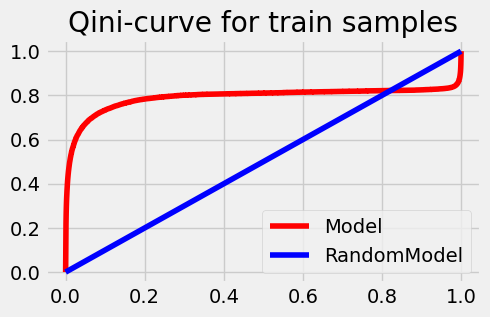

Qini score treatment - conversion for validation set: 683960.554


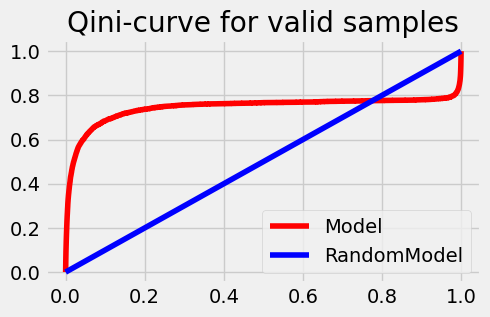

In [ ]:
# раcсчитываем qini score и рисуем qini curve на тренировочном и валидационном датасетах
# calculate the qini score and draw the qini curve on the training and validation datasets
print('Qini score treatment - conversion for train set: {:.3f}'.format(qini_count(ranked_train)))
qini_visual(ranked_train)

print('Qini score treatment - conversion for validation set: {:.3f}'.format(qini_count(ranked_val)))
qini_visual(ranked_val, title = 'valid')

Рисунки обоих кривых визуально совпадают - это говорит, что модель на валидационной выборке подтверждает предсказания на тренировочной выборке. Qini score здесь также хуже чем на S-модели. *uplift* эффект на последнем отрезке отсортированных *uplift score* отрицателен и это более резко выражено чем для S-модели.
_______________________________________________________________________________________________________________________

The two curves visually match, indicating that the model on the validation set confirms the predictions on the training set. The Qini score here is also worse than that of the S-model. The *uplift* effect on the last segment of the sorted *uplift score* is negative, and this is more pronounced than for the S-model.

In [ ]:
# записываем в  датасет для анализа результатов работы моделей результат работы T-learner
# write the result of the T-learner to the dataset for analyzing the results of the models

new_row = pd.DataFrame({
    'Model': ['T - learner'],
    'Qini score train': [round(qini_count(ranked_train), 3)],
    'Qini score validation': [round(qini_count(ranked_val), 3)]
})

Uplift_models_compare_treatment_conversion = pd.concat([Uplift_models_compare_treatment_conversion, new_row], ignore_index=True)

Uplift_models_compare_treatment_conversion

,Model,Qini score train,Qini score validation
0,S - learner,4693718.641,1173650.714
1,T - learner,3255811.694,683960.554


## **Построение моделей X-learner**

## **Building X-learner models**

На моей машине построение модели X-learner на обоих датасетах занимает больше суток и я решил сделать семплирование для тренировочного датасета - взять 10 часть от него для расчетов. Работа машины по построению модели заняла около 40 минут.
__________________________________________________________________________________________________________________________________________________

On my machine, building an X-learner model on both datasets takes over a day, so I decided to sample the training dataset—take 10% of it for calculations. The machine took about 40 minutes to build the model.

In [ ]:
# семплируем 1/10 выборки от обучающей выборки для облегчения расчетов
# sample 1/10 of the training sample to facilitate calculations

train_visit_expose_sample = train_visit_expose.sample(frac=0.1, random_state=42)

train_treat_conv_sample = train_treat_conv.sample(frac=0.1, random_state=42)

In [ ]:
# Создадим базовый X-learner для visit - expose датасета
# Create a basic X-learner for the visit-expose dataset
x_learner_visit = BaseXClassifier(
    outcome_learner=CatBoostClassifier(depth=5, random_seed=13, verbose=0),
    effect_learner=LinearRegression()
)

# Для обучения нам нужны датафрйем с факторами, таргет и колонка с фактом воздействия
# For training, we need dataframes with factors, target, and a column with the treatment indicator
feature_cols = ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']
target_col = 'exposure'
treatment_col = 'visit'

# учим модель на семплированной тренировочной выборке
# train the model on the sampled training set
x_learner_visit.fit(
    X=train_visit_expose_sample[feature_cols],
    treatment=train_visit_expose_sample[treatment_col],
    y=train_visit_expose_sample[target_col]
)

# Сделаем предсказание uplift-эффекта на обучающей выборке
# Let's make a prediction of the uplift effect on the training sample
uplift_vals = x_learner_visit.predict(np.array(train_visit_expose[feature_cols].values.copy()))
train_visit_expose['uplift_score'] = uplift_vals

# Сделаем предсказание uplift-эффекта на тестовой выборке
# Let's make a prediction of the uplift effect on the test sample
uplift_vals = x_learner_visit.predict(np.array(val_visit_expose[feature_cols].values.copy()))
val_visit_expose['uplift_score'] = uplift_vals

In [ ]:
# записываем, получившуюся модель в pkl файл
# write the resulting model to a pkl file
with open('x_learner_visit.pkl', 'wb') as f:
    pickle.dump(x_learner_visit, f)

In [ ]:
# реализуем функцию qini_calculate на тренировочной и валидационной выборках
# implement the qini_calculate function on the training and validation samples
ranked_train = qini_calculate(train_visit_expose, conversion = 'exposure')
ranked_val = qini_calculate(val_visit_expose, conversion = 'exposure')

Qini score visit - exposure for train set: 3506343.106


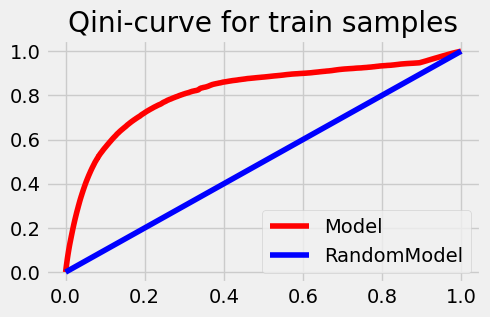

Qini score visit - exposure for validation set: 877615.783


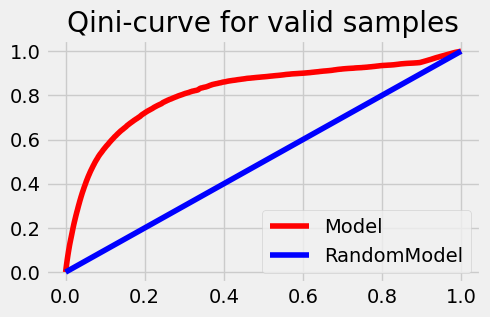

In [ ]:
# раcсчитываем qini score и рисуем qini curve на тренировочном и валидационном датасетах
# calculate the qini score and draw the qini curve on the training and validation datasets
print('Qini score visit - exposure for train set: {:.3f}'.format(qini_count(ranked_train)))
qini_visual(ranked_train)

print('Qini score visit - exposure for validation set: {:.3f}'.format(qini_count(ranked_val)))
qini_visual(ranked_val, title = 'valid')

*Qini score* по сравнению с S-моделью существенно выросло. Избавились от отрезка с отрицательным *uplift*-ом.
________________________________________________________________________________________

The Qini score has increased significantly compared to the S-model. We've eliminated the negative uplift segment.

In [ ]:
# записываем в датасет для анализа результатов работы моделей результат работы X-learner
# write the result of the X-learner to the dataset for analyzing the results of the models

new_row = pd.DataFrame({
    'Model': ['X - learner'],
    'Qini score train': [round(qini_count(ranked_train), 3)],
    'Qini score validation': [round(qini_count(ranked_val), 3)]
})

Uplift_models_compare_visit_exposure = pd.concat([Uplift_models_compare_visit_exposure, new_row], ignore_index=True)

Uplift_models_compare_visit_exposure

,Model,Qini score train,Qini score validation
0,S - learner,2465367.446,608991.155
1,T - learner,2031344.513,541990.935
2,X - learner,3506343.106,877615.783


In [ ]:
# Создадим базовый X-learner для treatment-conversion датасета
# Create a basic X-learner for the treatment-conversion dataset
x_learner_treatment = BaseXClassifier(
    outcome_learner=CatBoostClassifier(depth=5, random_seed=13, verbose=0),
    effect_learner=LinearRegression()
)

# Для обучения нам нужны датафрем с факторами, таргет и колонка с фактом воздействия
# For training, we need dataframes with factors, target, and a column with the treatment indicator
feature_cols = ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']
target_col = 'conversion'
treatment_col = 'treatment'

# учим модель на семплированной тренировочной выборке
# train the model on the sampled training set
x_learner_treatment.fit(
    X=train_treat_conv_sample[feature_cols],
    treatment=train_treat_conv_sample[treatment_col],
    y=train_treat_conv_sample[target_col]
)

# Сделаем предсказание uplift-эффекта на всей обучающей выборке
# make predictions for the uplift effect on the entire training sample
uplift_vals = x_learner_treatment.predict(np.array(train_treat_conv[feature_cols].values.copy()))
train_treat_conv['uplift_score'] = uplift_vals

# Сделаем предсказание uplift-эффекта на всей тестовой выборке
# make predictions for the uplift effect on the entire test sample
uplift_vals = x_learner_treatment.predict(np.array(val_treat_conv[feature_cols].values.copy()))
val_treat_conv['uplift_score'] = uplift_vals

In [ ]:
# записываем, получившуюся модель в pkl файл
# write the resulting model to a pkl file
with open('x_learner_treatment.pkl', 'wb') as f:
    pickle.dump(x_learner_visit, f)

In [ ]:
# реализуем функцию qini_calculate на тренировочной и валидационной выборках
# implement the qini_calculate function on the training and validation samples
ranked_train = qini_calculate(train_treat_conv)
ranked_val = qini_calculate(val_treat_conv)

Qini score visit - exposure for train set: 4895593.345


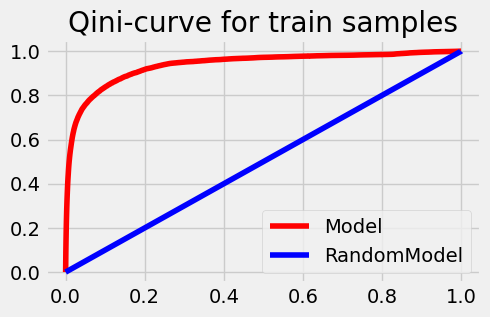

Qini score visit - exposure for validation set: 1222315.330


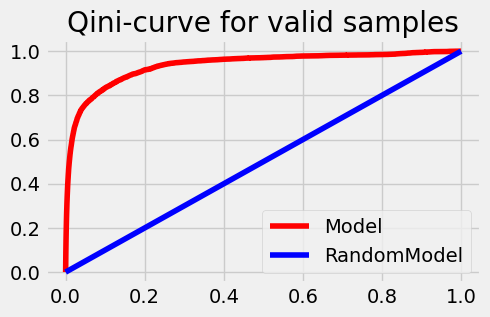

In [ ]:
# раcсчитываем qini score и рисуем qini curve на тренировочном и валидационном датасетах
# calculate the qini score and draw the qini curve on the training and validation datasets
print('Qini score visit - exposure for train set: {:.3f}'.format(qini_count(ranked_train)))
qini_visual(ranked_train)

print('Qini score visit - exposure for validation set: {:.3f}'.format(qini_count(ranked_val)))
qini_visual(ranked_val, title = 'valid')

Здесь также удалось увеличить qini score по сравнению с S-моделью.
_________________________________________________________________________________

Here we also managed to increase the qini score compared to the S-model.

In [ ]:
# записываем в датасет для анализа результатов работы моделей результат работы X-learner
# write the result of the X-learner to the dataset for analyzing the results of the models

new_row = pd.DataFrame({
    'Model': ['X - learner'],
    'Qini score train': [round(qini_count(ranked_train), 3)],
    'Qini score validation': [round(qini_count(ranked_val), 3)]
})

Uplift_models_compare_treatment_conversion = pd.concat([Uplift_models_compare_treatment_conversion, new_row], ignore_index=True)

Uplift_models_compare_treatment_conversion

,Model,Qini score train,Qini score validation
0,S - learner,4693718.641,1173650.714
1,T - learner,3255811.694,683960.554
2,X - learner,4895593.345,1222315.330


## **Построение моделей R-learner**

## **Building R-learner models**

In [ ]:
# Создадим базовый R-learner для visit-expose датасета
# Create a basic R-learner for the visit-expose dataset
r_learner_visit = BaseRClassifier(
    outcome_learner=CatBoostClassifier(depth=5, random_seed=13, verbose=0),
    effect_learner=LinearRegression(),
    random_state=42
)

# Для обучения нам нужны датафрем с факторами, таргет и колонка с фактом воздействия
# For training, we need dataframes with factors, target, and a column with the treatment indicator
feature_cols = ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']
target_col = 'exposure'
treatment_col = 'visit'

# учим модель на семплированной тренировочной выборке
# train the model on the sampled training set
r_learner_visit.fit(X=train_visit_expose_sample[feature_cols],
              treatment=train_visit_expose_sample[treatment_col],
              y=train_visit_expose_sample[target_col])

# Сделаем предсказание uplift-эффекта на всей обучающей выборке
# make predictions for the uplift effect on the entire training sample
uplift_vals = r_learner_visit.predict(np.array(train_visit_expose[feature_cols].values.copy()))
train_visit_expose['uplift_score'] = uplift_vals

# Сделаем предсказание uplift-эффекта на квсей тестовой выборке
# make predictions for the uplift effect on the entire validation sample
uplift_vals = r_learner_visit.predict(np.array(val_visit_expose[feature_cols].values.copy()))
val_visit_expose['uplift_score'] = uplift_vals

In [ ]:
# записываем, получившуюся модель в pkl файл
# write the resulting model to a pkl file
with open('r_learner_visit.pkl', 'wb') as f:
    pickle.dump(r_learner_visit, f)

In [ ]:
# реализуем функцию qini_calculate на тренировочной и валидационной выборках
# implement the qini_calculate function on the training and validation samples
ranked_train = qini_calculate(train_visit_expose, conversion = 'exposure')
ranked_val = qini_calculate(val_visit_expose, conversion = 'exposure')

Qini score visit - exposure for train set: 3217531.905


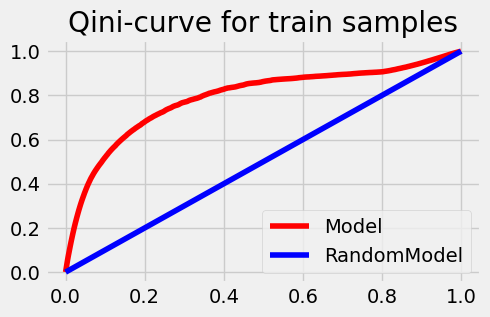

Qini score visit - exposure for validation set: 805556.074


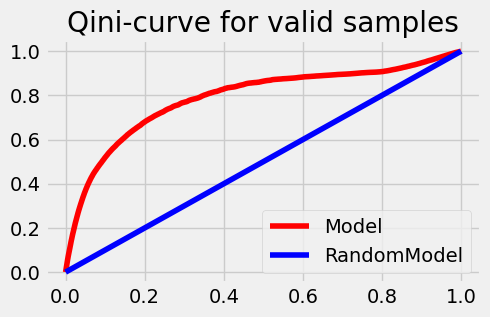

In [ ]:
# раcсчитываем qini score и рисуем qini curve на тренировочном и валидационном датасетах
# calculate the qini score and draw the qini curve on the training and validation datasets
print('Qini score visit - exposure for train set: {:.3f}'.format(qini_count(ranked_train)))
qini_visual(ranked_train)

print('Qini score visit - exposure for validation set: {:.3f}'.format(qini_count(ranked_val)))
qini_visual(ranked_val, title = 'valid')

*Qini score* немного хуже чем на X-модели. Отрицательного *uplift* не наблюдаем.
_______________________________________________________________________________________________

The Qini score is slightly worse than on the X-model. No negative uplift is observed.

In [ ]:
# записываем в датасет для анализа результатов работы моделей результат работы R-learner
# write the result of the R-learner to the dataset for analyzing the results of the models

new_row = pd.DataFrame({
    'Model': ['R - learner'],
    'Qini score train': [round(qini_count(ranked_train), 3)],
    'Qini score validation': [round(qini_count(ranked_val), 3)]
})

Uplift_models_compare_visit_exposure = pd.concat([Uplift_models_compare_visit_exposure, new_row], ignore_index=True)

Uplift_models_compare_visit_exposure

,Model,Qini score train,Qini score validation
0,S - learner,2465367.446,608991.155
1,T - learner,2031344.513,541990.935
2,X - learner,3506343.106,877615.783
3,R - learner,3217531.905,805556.074


In [ ]:
# Создадим базовый R-learner для treatment-conversion датасета
# Create a basic R-learner for the treatment-conversion dataset
r_learner_treatment = BaseRClassifier(
    outcome_learner=CatBoostClassifier(depth=5, random_seed=13, verbose=0),
    effect_learner=LinearRegression(),
    random_state=42
)

# Для обучения нам нужны датафрем с факторами, таргет и колонка с фактом воздействия
# For training, we need dataframes with factors, target, and a column with the treatment indicator
feature_cols = ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']
target_col = 'conversion'
treatment_col = 'treatment'

# учим модель на семплированной тренировочной выборке
# train the model on the sampled training set
r_learner_treatment.fit(X=train_treat_conv_sample[feature_cols],
              treatment=train_treat_conv_sample[treatment_col],
              y=train_treat_conv_sample[target_col])

# Сделаем предсказание uplift-эффекта на обучающей выборке
# make predictions for the uplift effect on the training sample
uplift_vals = r_learner_treatment.predict(np.array(train_treat_conv[feature_cols].values.copy()))
train_treat_conv['uplift_score'] = uplift_vals

# Сделаем предсказание uplift-эффекта на тестовой выборке
# make predictions for the uplift effect on the validation sample
uplift_vals = r_learner_treatment.predict(np.array(val_treat_conv[feature_cols].values.copy()))
val_treat_conv['uplift_score'] = uplift_vals

In [ ]:
# записываем, получившуюся модель в pkl файл
# write the resulting model to a pkl file
with open('r_learner_treatment.pkl', 'wb') as f:
    pickle.dump(r_learner_treatment, f)

In [ ]:
# реализуем функцию qini_calculate на тренировочной и валидационной выборках
# implement the qini_calculate function on the training and validation samples
ranked_train = qini_calculate(train_treat_conv)
ranked_val = qini_calculate(val_treat_conv)

Qini score visit - exposure for train set: 4834141.380


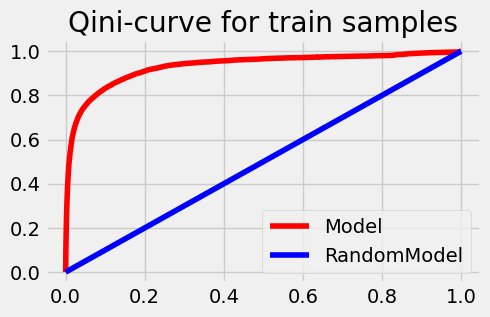

Qini score visit - exposure for validation set: 1205271.516


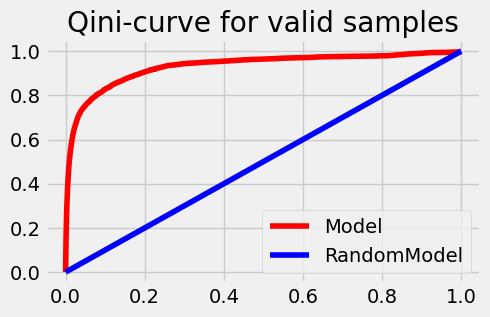

In [ ]:
# раcсчитываем qini score и рисуем qini curve на тренировочном и валидационном датасетах
# calculate the qini score and draw the qini curve on the training and validation datasets
print('Qini score visit - exposure for train set: {:.3f}'.format(qini_count(ranked_train)))
qini_visual(ranked_train)

print('Qini score visit - exposure for validation set: {:.3f}'.format(qini_count(ranked_val)))
qini_visual(ranked_val, title = 'valid')

*Quni score* почти на том же уровне, что для X модели.
_______________________________________________________________

*Quni score* is almost at the same level as for the X model.

In [ ]:
# записываем в датасет для анализа результатов работы моделей результат работы R-learner
# write the result of the R-learner to the dataset for analyzing the results of the models
new_row = pd.DataFrame({
    'Model': ['R - learner'],
    'Qini score train': [round(qini_count(ranked_train), 3)],
    'Qini score validation': [round(qini_count(ranked_val), 3)]
})

Uplift_models_compare_treatment_conversion = pd.concat([Uplift_models_compare_treatment_conversion, new_row], ignore_index=True)

In [29]:
Uplift_models_compare_treatment_conversion

,Model,Qini score train,Qini score validation
0,S - learner,4693718.641,1173650.714
1,T - learner,3255811.694,683960.554
2,X - learner,4895593.345,1222315.330
3,R - learner,4834141.380,1205271.516


## **Построение моделей UpliftRandomForest**

## **Building UpliftRandomForest Models**

Здесь также расчет модели и прогнозов на основании этой модели на машине занимал много времени (возможно сутки или больше) и я взял для постраения модели семплированную 1/100 тренировочного джатасета.
______________________________________________________________________________________________________

Here, too, calculating the model and forecasts based on this model on a machine took a lot of time (possibly a day or more), and I took a sampled 1/100 of the training jataset to build the model.

In [ ]:
# семплируем 1/100 выборки от обучающей выборки для облегчения расчетов
# sample 1/100 of the training sample to facilitate calculations
train_visit_expose_sample = train_visit_expose.sample(frac=0.01, random_state=42)

val_visit_expose_sample = val_visit_expose.sample(frac=0.01, random_state=42)

In [ ]:
# Создаем случайный лес для visit - expose датасета
# Create a random forest for the visit-expose dataset
uplift_forest_visit = UpliftRandomForestClassifier(
    n_estimators=100, max_depth=5, min_samples_leaf=100, 
    min_samples_treatment=50,
    n_reg=100, evaluationFunction='ED', 
    control_name='0', random_state=42
)

# Для обучения нам нужны датафрем с факторами, таргет и колонка с фактом воздействия
# For training, we need dataframes with factors, target, and a column with the treatment indicator  
feature_cols = ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']
target_col = 'exposure'
treatment_col = 'visit'


# Обучаем модель Random Forest на семплированной обучающей выборке
# Train the Random Forest model on the sampled training set
uplift_forest_visit.fit(
    train_visit_expose_sample[feature_cols].values,
    treatment=train_visit_expose_sample[treatment_col].apply(str).values,
    y=train_visit_expose_sample[target_col].values
)

In [ ]:
# записываем, получившуюся модель в pkl файл
# write the resulting model to a pkl file
with open('uplift_forest_visit.pkl', 'wb') as f:
    pickle.dump(uplift_forest_visit, f)

In [ ]:
# Сделаем предсказание uplift-эффекта на семплированной обучающей выборке
# Let's make a prediction of the uplift effect on the sampled training sample
uplift_vals = uplift_forest_visit_expose_sample.predict(np.array(train_visit_expose_sample[feature_cols].values.copy()))
train_visit_expose_sample['uplift_score'] = uplift_vals

# Сделаем предсказание uplift-эффекта на семплированной тестовой выборке
# Let's make a prediction of the uplift effect on the sampled validation sample
uplift_vals = uplift_forest_visit_expose_sample.predict(np.array(val_visit_expose_sample[feature_cols].values.copy()))
val_visit_expose_sample['uplift_score'] = uplift_vals

Qini score visit - exposure for train set: -620264.980


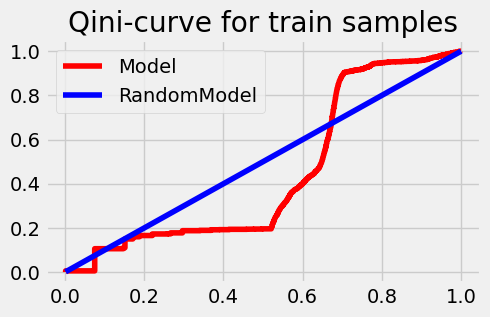

Qini score visit - exposure for validation set: -149373.382


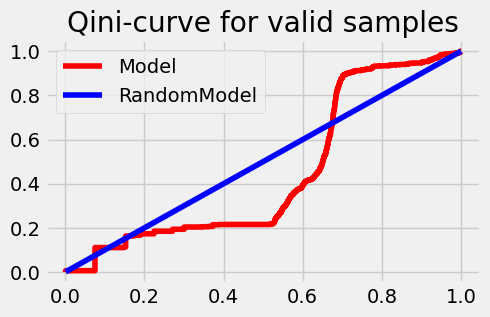

In [ ]:
# реализуем функцию qini_calculate на семплированных тренировочной и валидационной выборках
# implement the qini_calculate function on the sampled training and validation samples
ranked_train = qini_calculate(train_visit_expose_sample, conversion = 'exposure')
ranked_val = qini_calculate(val_visit_expose_sample, conversion = 'exposure')

# раcсчитываем qini score и рисуем qini curve на тренировочном и валидационном датасетах
# calculate the qini score and draw the qini curve on the training and validation datasets
print('Qini score visit - exposure for train set: {:.3f}'.format(qini_count(ranked_train)*100))
qini_visual(ranked_train)

print('Qini score visit - exposure for validation set: {:.3f}'.format(qini_count(ranked_val)*100))
qini_visual(ranked_val, title = 'valid')

*Qini curve* показывает отрицательный *uplift* на существенном отрезке. *Qini score* показывает отрицательный результат. Модель нельзя использовать для расчета *uplift* эффекта.
Я думаю, что т.к. у нас в модели число клиентов к которым был совершен визит и клиентов (4,7 % записей) и клиентов, у которых мы наблюдали эффект exposure (3,1 % записей) величины одного порядка и практически невозможно построить вилки сравнений по features для предсказания отношения клиента к группам с exposure равным/ не равным - 1/0 соответственно.
_____________________________________________________________________________________________________________________________________________________________________________

*The Qini curve* shows negative *uplift* over a significant period. The Qini score shows a negative result. The model cannot be used to calculate the uplift effect.
I should say that becaus that since our model has a similar number of clients visited (4.7% of records) and clients for whom we observed an exposure effect (3.1% of records), it is practically impossible to construct comparison forks by features to predict client attitudes toward groups with equal/not equal exposure—1/0, respectively.

In [ ]:
# записываем в датасет для анализа результатов работы моделей результат работы Random Forest
# write the result of the Random Forest to the dataset for analyzing the results of the models

new_row = pd.DataFrame({
    'Model': ['Uplift - forest'],
    'Qini score train': [round((qini_count(ranked_train)*100), 3)],
    'Qini score validation': [round((qini_count(ranked_val)*100), 3)]
})

Uplift_models_compare_visit_exposure = pd.concat([Uplift_models_compare_visit_exposure, new_row], ignore_index=True)

In [31]:
Uplift_models_compare_visit_exposure

,Model,Qini score train,Qini score validation
0,S-learner,2465367.446,608991.155
1,T-learner,2031344.513,541990.935
2,X-learner,3506343.106,877615.783
3,R-learner,3217531.905,805556.074
4,Uplift - forest,-620264.980,-149373.382


In [ ]:
# Запишем результаты работы моделей visit-exposure в csv файл
# Write the results of the visit-exposure models to a csv file
Uplift_models_compare_visit_exposure.to_csv('visit_models_compare.csv', index=False)

In [ ]:
# семплируем 1/10 выборки от обучающей выборки для облегчения расчетов
# sample 1/10 of the training sample to facilitate calculations
train_treat_conv_sample = train_treat_conv.sample(frac=0.1, random_state=42)

val_treat_conv_sample = val_treat_conv.sample(frac=0.1, random_state=42)

In [ ]:
# Создаем случайный лес для treat - conversion датасета
# Create a random forest for the treatment-conversion dataset
uplift_forest_treat = UpliftRandomForestClassifier(
    n_estimators=100, max_depth=5, min_samples_leaf=100, 
    min_samples_treatment=50,
    n_reg=100, evaluationFunction='ED', 
    control_name='0', random_state=42
)

# Для обучения нам нужны датафрем с факторами, таргет и колонка с фактом воздействия
# For training, we need dataframes with factors, target, and a column with the treatment indicator
feature_cols = ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']
target_col = 'conversion'
treatment_col = 'treatment'


# Обучаем модель Random Forest
# Train the Random Forest model
uplift_forest_treat.fit(
    train_treat_conv_sample[feature_cols].values,
    treatment=train_treat_conv_sample[treatment_col].apply(str).values,
    y=train_treat_conv_sample[target_col].values
)

In [ ]:
# записываем, получившуюся модель в pkl файл
# write the resulting model to a pkl file
with open('uplift_forest_treat.pkl', 'wb') as f:
    pickle.dump(uplift_forest_treat, f)

In [ ]:

# Сделаем предсказание uplift-эффекта на семплированной обучающей выборке
# Let's make a prediction of the uplift effect on the sampled training sample
uplift_vals = uplift_forest_treat.predict(np.array(train_treat_conv_sample[feature_cols].values.copy()))
train_treat_conv_sample['uplift_score'] = uplift_vals

# Сделаем предсказание uplift-эффекта на семплированной тестовой выборке
# Let's make a prediction of the uplift effect on the sampled validation sample
uplift_vals = uplift_forest_treat.predict(np.array(val_treat_conv_sample[feature_cols].values.copy()))
val_treat_conv_sample['uplift_score'] = uplift_vals

Qini score treatment-conversion for train set: 4856454.859


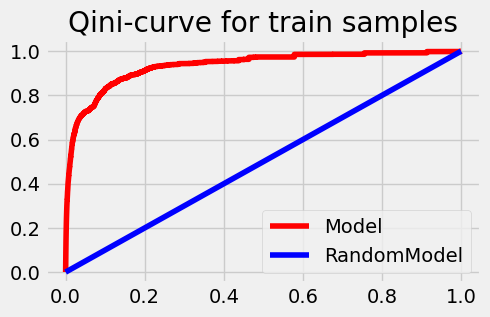

Qini score treatment-conversion for validation set: 1225603.621


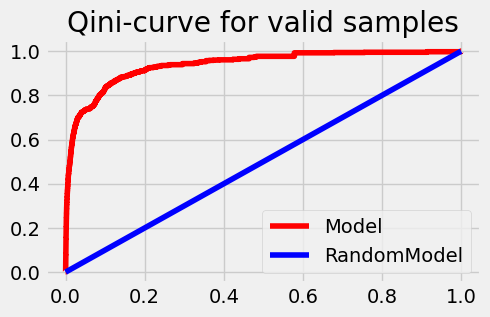

In [ ]:
# реализуем функцию qini_calculate на тренировочной и валидационной выборках
# implement the qini_calculate function on the training and validation samples
ranked_train = qini_calculate(train_treat_conv_sample)
ranked_val = qini_calculate(val_treat_conv_sample)

# раcсчитываем qini score и рисуем qini curve на тренировочном и валидационном датасетах
# calculate the qini score and draw the qini curve on the training and validation datasets
print('Qini score treatment-conversion for train set: {:.3f}'.format(qini_count(ranked_train)*10))
qini_visual(ranked_train)

print('Qini score treatment-conversion for validation set: {:.3f}'.format(qini_count(ranked_val)*10))
qini_visual(ranked_val, title = 'valid')

In [ ]:
# записываем в датасет для анализа результатов работы моделей результат работы Random Forest
#  write the result of the Random Forest to the dataset for analyzing the results of the models

new_row = pd.DataFrame({
    'Model': ['Uplift - forest'],
    'Qini score train': [round(qini_count(ranked_train)*10, 3)],
    'Qini score validation': [round(qini_count(ranked_val)*10, 3)]
})

Uplift_models_compare_treatment_conversion = pd.concat([Uplift_models_compare_treatment_conversion, new_row], ignore_index=True)

Uplift_models_compare_treatment_conversion

,Model,Qini score train,Qini score validation
0,S-learner,4693718.641,1173650.714
1,T-learner,3255811.694,683960.554
2,X-learner,4895593.345,1222315.330
3,R-learner,4834141.380,1205271.516
4,Uplift - forest,4856454.859,1225603.621


In [ ]:
# Запишем результаты работы моделей treatment-conversion в csv файл
# Write the results of the treatment-conversion models to a csv file
Uplift_models_compare_treatment_conversion.to_csv('treatment_models_compare.csv', index=False)

## **Окончательныйе выводы по моделям**

## **Final conclusions about the models**

In [ ]:
# модели visit - exposure
# visit - exposure models

Uplift_models_compare_visit_exposure

,Model,Qini score train,Qini score validation
0,S-learner,2465367.446,608991.155
1,T-learner,2031344.513,541990.935
2,X-learner,3506343.106,877615.783
3,R-learner,3217531.905,805556.074
4,Uplift - forest,-620264.980,-149373.382


Для оценки *uplift* эффекта от фактора *visit* на *exposure* лучше всего подходят модели X-learner и R-learner. Это связано с высокими показателями *qini score*.
__________________________________________________________________________________

The X-learner and R-learner models are best suited for assessing the uplifting effect of the visit factor on exposure. This is due to their high qini scores.

In [ ]:
# модели treatment - conversion
# treatment - conversion models

Uplift_models_compare_treatment_conversion

,Model,Qini score train,Qini score validation
0,S-learner,4693718.641,1173650.714
1,T-learner,3255811.694,683960.554
2,X-learner,4895593.345,1222315.330
3,R-learner,4834141.380,1205271.516
4,Uplift - forest,4856454.859,1225603.621


Для оценки *uplift* эффекта от фактора *treatment* на *conversion* лучше всего подходят модели X-learner и R-learner. Это связано с высокими показателями *qini score* и отсутствием на *qini curve* отрезков с отрицательным *uplift*. Модель *Uplift forest* тоже показала высокий qini score, но ее недостаток - громоздкие вычисления, затрудняющие при обработке больших данных получение быстрого результата.
_________________________________________________________________________________________________________________________

Modele X-learner i R-learner najlepiej nadają się do oceny wpływu współczynnika leczenia na konwersję. Wynika to z ich wysokich wyników qini i braku ujemnych segmentów wzrostu na krzywej qini. Model lasu Uplift również wykazał wysoki wynik qini, ale jego wadą są uciążliwe obliczenia, które utrudniają szybkie uzyskiwanie wyników podczas przetwarzania dużych zbiorów danych.